# Bokeh: the out-of-focus image of a camera lens

A camera lens is sharp at one distance only. Everything nearer or farther is
imaged as a blur, and the look of those blurs, smooth or busy, round or
squeezed, plain or ringed, is what photographers call bokeh (from the
Japanese *boke*, blur). It is a property of the lens, not of the scene: two
lenses of the same focal length and F-number can render the same background
very differently.

Geometrically, the blur of a point is a shadow of the pupil. Each ray from
the point crosses the sensor at a place set by where it passed through the
lens, so the outline of the blur is the outline of the pupil as seen from
the point, and its brightness is the number of rays per area. That one
picture explains all of the effects in this notebook:

1. the lens: a fast double Gauss (50 mm, f/1.8), designed for this
   notebook,
2. the size of the blur, the circle of confusion, from a thin lens, from
   the pupils and from real rays,
3. spherical aberration: why the blur has a bright rim (soap bubble bokeh)
   on one side of the focus and a soft edge on the other, doubled lines
   (nervous bokeh), and when the blur needs wave optics,
4. mechanical vignetting: the cat's eye at the edge of the frame and the
   light it costs,
5. onion rings: the concentric rings that small ripples of moulded
   aspheres leave in the blur, from rays and from waves,
6. apodization: the graded filter of the "smooth trans focus" portrait
   lenses, the T-number it costs and what it does to the sharp image,
7. a rendered night scene of fairy lights, in three colours.

The tools are in `pyoptics.photography`: the lens (`double_gauss()`,
`focus()`), blur sizes, rays from a point through the whole aperture
(`point_footprint()`, `splat()`), vignetting circles, the geometric and wave
optical profiles of a defocused point, a rippled surface for the ray trace
and the apodizer formulas.

Sign convention (as in `raytrace`): the background (farther than the focused
distance) is imaged in front of the sensor, so the sensor sees a beam that
has already passed its focus, W020 < 0; the foreground is imaged behind the
sensor, W020 > 0. A lens with undercorrected spherical aberration has
W040 < 0.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import photography as ph
from pyoptics import raytrace as rt
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(90)
WL_F, WL_D, WL_C = 486.13e-6, ph.D_LINE, 656.27e-6   # mm

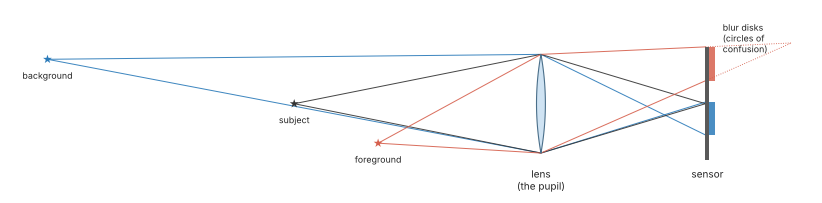

In [2]:
fig, ax = plt.subplots(figsize=(13, 4.2))
sketch.bokeh_formation(ax)
plt.show()

## 1. The lens: a fast double Gauss

Most standard lenses for 35 mm cameras since the 1950s are double Gauss
lenses: two thick negative meniscus groups facing the stop, with a positive
lens outside each, almost symmetric about the stop. The symmetry cancels
coma, distortion and lateral colour to a large degree, and the thick
menisci flatten the field. What is left at large apertures is spherical
aberration, mostly the zonal kind, and oblique spherical aberration off the
axis.

The lens of this notebook was designed with
`lens_optimization.DampedLeastSquares`, starting from a slower textbook
double Gauss, with the curvatures and spacings varied for the F, d and C
lines over the field and the aperture growing in stages up to f/1.8 (as in
notebook 58). The glasses are N-LAK9 and N-SF5. The clear apertures were set
afterwards, as in a real lens, to keep the front and rear elements small: the
full axial beam passes, oblique beams are cut.

In [3]:
lens = ph.double_gauss(1.8)
p = lens.paraxial()
m_p = p.xp_radius/p.ep_radius
names = {}
print(" surf      R (mm)   t (mm)   glass    semi-diameter (mm)")
for i, s in enumerate(lens.surfaces):
    g = "air" if not s.changes_medium or s.n_after == 1.0 else s.material.__self__.name
    R = "inf" if np.isinf(s.R) else "{:8.3f}".format(s.R)
    print("{:4d}{} {:>9s} {:8.3f}   {:7s} {:6.2f}".format(i, "*" if i == lens.stop_index else " ", R,
                                                        s.thickness, g, s.semi_diameter))
m_p = p.xp_radius/p.ep_radius
print("efl {:.3f} mm, f/{:.2f}, back focal length {:.2f} mm".format(p.efl, p.f_number, p.bfl))
print("entrance pupil: {:.2f} mm behind the first vertex, diameter {:.2f} mm".format(p.ep_z, 2*p.ep_radius))
print("exit pupil: {:.2f} mm, diameter {:.2f} mm, pupil magnification m_p = {:.3f}".format(
    p.xp_z, 2*p.xp_radius, m_p))
print("Seidel spherical aberration W040 = {:.1f} waves at f/1.8".format(lens.seidel().W040))
f_numbers = [1.8, 2.0, 2.8, 4.0, 5.6, 8.0]
spots = {}
for N in f_numbers:
    s = ph.focus(ph.double_gauss(N))
    spots[N] = [s.spot_diagram(f*s.max_field, N=41).rms*1e3 for f in (0.0, 0.7)]
    spots[N] += [np.sqrt(np.mean([s.with_wavelength(w).spot_diagram(f*s.max_field, N=41).rms**2
                                  for w in (WL_F, WL_D, WL_C)]))*1e3 for f in (0.0, 0.7)]
    print("f/{:3.1f}: RMS spot radius {:5.1f} um on the axis, {:5.1f} um at 70 % field (d line); "
          "{:5.1f} and {:5.1f} um for F, d and C together".format(N, *spots[N]))

 surf      R (mm)   t (mm)   glass    semi-diameter (mm)
   0     34.135    7.030   N-LAK9   17.00
   1     62.192    0.300   air      16.00
   2     18.549    3.153   N-LAK9   13.80
   3     18.476    1.500   N-SF5    12.90
   4     14.669   10.566   air      11.70
   5*       inf    3.858   air       9.98
   6    -23.316    1.500   N-SF5    10.90
   7     47.669   10.970   N-LAK9   12.80
   8    -29.340    0.300   air      13.60
   9     54.812    5.887   N-LAK9   13.60
  10   -116.032   36.000   air      13.30
efl 49.999 mm, f/1.80, back focal length 36.50 mm
entrance pupil: 27.29 mm behind the first vertex, diameter 27.78 mm
exit pupil: 19.98 mm, diameter 34.21 mm, pupil magnification m_p = 1.232
Seidel spherical aberration W040 = -31.7 waves at f/1.8


f/1.8: RMS spot radius  36.7 um on the axis,  63.0 um at 70 % field (d line);  37.8 and  62.9 um for F, d and C together


f/2.0: RMS spot radius  21.2 um on the axis,  46.2 um at 70 % field (d line);  23.1 and  46.4 um for F, d and C together


f/2.8: RMS spot radius  10.1 um on the axis,  41.0 um at 70 % field (d line);  12.4 and  41.4 um for F, d and C together


f/4.0: RMS spot radius   3.8 um on the axis,  32.8 um at 70 % field (d line);   6.5 and  33.1 um for F, d and C together


f/5.6: RMS spot radius   1.4 um on the axis,  24.7 um at 70 % field (d line);   4.1 and  25.0 um for F, d and C together


f/8.0: RMS spot radius   0.5 um on the axis,  17.8 um at 70 % field (d line);   2.7 and  18.0 um for F, d and C together


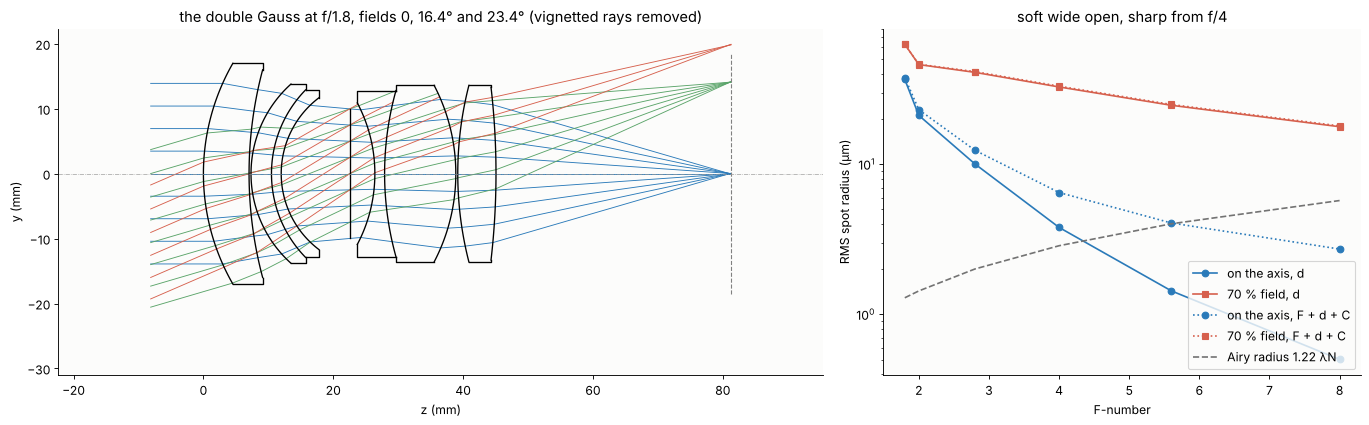

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(17, 5.2), layout="constrained", width_ratios=[1.6, 1])
draw_lens = ph.focus(lens)
draw_lens.draw(ax[0], fields=[0.0, 0.7*lens.max_field, lens.max_field], n_rays=9,
               colors=[BLUE, GREEN, RED])
ax[0].set_aspect("equal")
ax[0].set_xlabel("z (mm)")
ax[0].set_ylabel("y (mm)")
ax[0].set_title("the double Gauss at f/1.8, fields 0, 16.4° and 23.4° (vignetted rays removed)")
ax[1].semilogy(f_numbers, [spots[N][0] for N in f_numbers], "o-", color=BLUE, label="on the axis, d")
ax[1].semilogy(f_numbers, [spots[N][1] for N in f_numbers], "s-", color=RED, label="70 % field, d")
ax[1].semilogy(f_numbers, [spots[N][2] for N in f_numbers], "o:", color=BLUE, label="on the axis, F + d + C")
ax[1].semilogy(f_numbers, [spots[N][3] for N in f_numbers], "s:", color=RED, label="70 % field, F + d + C")
ax[1].semilogy(f_numbers, [1.22*WL_D*N*1e3 for N in f_numbers], "--", color=GREY,
               label="Airy radius 1.22 λN")
ax[1].set_xlabel("F-number")
ax[1].set_ylabel("RMS spot radius (µm)")
ax[1].set_title("soft wide open, sharp from f/4")
ax[1].legend()
plt.show()

The paraxial data are those of a 50 mm f/1.8 lens with a back focal
length of 36.5 mm. The exit pupil is 1.23 times larger than the entrance
pupil. Seidel's W040 of −32 waves at f/1.8 is mostly balanced by the higher
orders: the best focus lies between the paraxial and the marginal focus, and
the RMS spot on the axis is 37 µm wide open (d line), 10 µm at f/2.8 and
4 µm at f/4. Off the axis the lens is softer, 63 µm at 70 % of the field at
f/1.8. Commercial lenses of this type do better off the axis, but they are
soft wide open too. The lens is good enough here: every effect in this
notebook comes from the blur of points far from focus, which is a hundred
times larger than these spots.

## 2. The size of the blur

A thin lens of focal length f and F-number N, focused at the distance
$s_f$, images a point at the distance $s$ as a disk of diameter

$$c = \frac{f^2}{N}\,\frac{|s - s_f|}{s\,(s_f - f)},$$

the circle of confusion (`blur_diameter()`). For a point at infinity it is
$f^2/(N(s_f - f))$, which only depends on the focus distance. For a thick
lens, the light leaves through the exit pupil, which can be larger or
smaller than the entrance pupil (pupil magnification $m_p$) and lies
somewhere else. With Newton's distances, $x$ of the point in front of the
front focal point and $x_s$ of the sensor behind the rear focal point, the
image lies at $x' = f^2/x$ and

$$c = m_p D\,\frac{|x_s - x'|}{x' + m_p f},$$

with the entrance pupil diameter $D$ (`blur_diameter_pupils()`). This is
exact in first order, and for $m_p = 1$ with the distances measured from the
principal planes it is the thin lens formula. Here the lens is focused
(paraxially) on a point 1 m in front of its first vertex, and points from
0.35 m to infinity are compared.

In [5]:
S1 = ph.focus(lens, 1000.0)                 # focused at 1 m (from the front vertex), smallest spot
S1p = rt.System(lens.surfaces, 5, WL_D, object_distance=1000.0, object_height=1.0).at_paraxial_focus()
p1 = S1p.paraxial()
cp = p1.cardinal_points
x_sensor = S1p.vertex_z[-1] + S1p.surfaces[-1].thickness - cp.F_prime
print("focused at 1 m: the lens moves {:.2f} mm away from the sensor (paraxial focus)".format(
    S1p.surfaces[-1].thickness - lens.at_paraxial_focus().surfaces[-1].thickness))
print("the smallest spot at f/1.8 lies {:.2f} mm in front of the paraxial focus".format(
    S1p.surfaces[-1].thickness - S1.surfaces[-1].thickness))


def at_distance(system, dist):
    """The focused system looking at a point at the distance dist (mm from the first vertex)."""
    if np.isinf(dist):
        return rt.System(system.surfaces, system.stop_index, system.wavelength, field_angle=0.1)
    return rt.System(system.surfaces, system.stop_index, system.wavelength, object_distance=dist,
                     object_height=1.0)


def blur_first_order(system, dist):
    """Paraxial blur diameter of a point at dist on the system's sensor."""
    t = at_distance(system, dist)
    pm = t.paraxial()
    return 2*abs(pm.marginal[-1, 0] + pm.marginal[-1, 1]*t.surfaces[-1].thickness)


def traced_diameter(system, n_rays=40000, apodization=None):
    """Diameter of the blur from real rays: twice the radius that holds 99 % of the power."""
    fp = ph.point_footprint(system, 0.0, n_rays, rng, apodization)
    r = np.hypot(fp.x - np.average(fp.x, weights=fp.weight), fp.y - np.average(fp.y, weights=fp.weight))
    order = np.argsort(r)
    c = np.cumsum(fp.weight[order])
    return 2*r[order][np.searchsorted(c, 0.99*c[-1])]


dists = np.array([350.0, 500.0, 700.0, 1500.0, 3000.0, 10000.0, np.inf])
S8 = ph.double_gauss(8.0)
S8.surfaces[-1].thickness = S1p.surfaces[-1].thickness     # the same paraxial sensor
rows = []
for d in dists:
    c_par = blur_first_order(S1p, d)
    c_pup = ph.blur_diameter_pupils(p1.efl, 2*p1.ep_radius, m_p, x_sensor, d + cp.F)
    c_thin = ph.blur_diameter(p1.efl, 1.8, 1000.0 + cp.H, d + cp.H)
    rows.append((d, c_thin, c_pup, c_par, traced_diameter(at_distance(S8, d))*8/1.8,
                 traced_diameter(at_distance(S1p, d))))
print(" distance   thin lens   pupils   paraxial trace   real rays f/8 (x 8/1.8)   real rays f/1.8")
for d, *c in rows:
    print("{:>8s} mm  {:7.3f}   {:7.3f}   {:7.3f}          {:7.3f}                  {:7.3f}".format(
        "inf" if np.isinf(d) else "{:.0f}".format(d), *c))
rows = np.array(rows)
print("largest |pupils - paraxial trace|: {:.1e} mm".format(np.max(np.abs(rows[:, 2] - rows[:, 3]))))

focused at 1 m: the lens moves 2.53 mm away from the sensor (paraxial focus)
the smallest spot at f/1.8 lies 0.33 mm in front of the paraxial focus


 distance   thin lens   pupils   paraxial trace   real rays f/8 (x 8/1.8)   real rays f/1.8
     350 mm    2.366     2.425     2.425            2.385                    2.148
     500 mm    1.311     1.335     1.335            1.298                    1.029
     700 mm    0.573     0.581     0.581            0.548                    0.257
    1500 mm    0.458     0.461     0.461            0.488                    0.808
    3000 mm    0.927     0.930     0.930            0.955                    1.285
   10000 mm    1.262     1.263     1.263            1.287                    1.626
     inf mm    1.408     1.408     1.408            1.430                    1.772
largest |pupils - paraxial trace|: 1.7e-14 mm


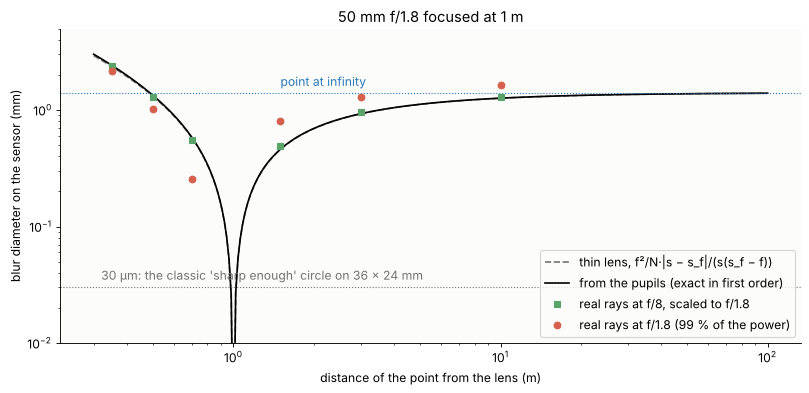

In [6]:
dd = np.logspace(np.log10(300), 5, 300)
fig, ax = plt.subplots(figsize=(10, 4.8), layout="constrained")
ax.loglog(dd/1000, ph.blur_diameter(p1.efl, 1.8, 1000.0 + cp.H, dd + cp.H), color=GREY, ls="--",
          label="thin lens, f²/N·|s − s_f|/(s(s_f − f))")
ax.loglog(dd/1000, ph.blur_diameter_pupils(p1.efl, 2*p1.ep_radius, m_p, x_sensor, dd + cp.F),
          color="k", label="from the pupils (exact in first order)")
ax.loglog(rows[:-1, 0]/1000, rows[:-1, 4], "s", color=GREEN, label="real rays at f/8, scaled to f/1.8")
ax.loglog(rows[:-1, 0]/1000, rows[:-1, 5], "o", color=RED, label="real rays at f/1.8 (99 % of the power)")
ax.axhline(rows[-1, 3], color=BLUE, lw=1, ls=":")
ax.text(1.5, rows[-1, 3]*1.08, "point at infinity", color=BLUE, ha="left", va="bottom")
ax.axhline(0.03, color=GREY, lw=1, ls=":")
ax.text(0.32, 0.033, "30 µm: the classic 'sharp enough' circle on 36 × 24 mm", color=GREY, va="bottom")
ax.set_xlabel("distance of the point from the lens (m)")
ax.set_ylabel("blur diameter on the sensor (mm)")
ax.set_title("50 mm f/1.8 focused at 1 m")
ax.set_ylim(0.01, 5)
ax.legend(loc="lower right")
plt.show()

The formula from the pupils agrees with the paraxial ray trace to
2e-14 mm, and the thin lens formula with distances from the principal
planes is within 2.5 %, since the pupils of this lens are close to the
principal planes. Real rays at f/8, scaled to the f/1.8 aperture, are within
6 % of first order. Wide open they are not: at f/1.8 the blur of the
background is 26 % larger than first order says, and points just in front
of the focus are much smaller than predicted. The spherical aberration has
moved the sharpest image 0.33 mm in front of the paraxial focus, and it
changes the inside of the blur as well, which is the subject of the next
section.

The blur grows quickly towards near points and saturates towards infinity:
everything beyond 10 m has nearly the same blur. A 1.4 mm disk is about 4 %
of the width of a 36 × 24 mm frame.

## 3. Spherical aberration: soap bubbles and soft edges

With spherical aberration the rays through different zones of the pupil
focus at different distances. In a plane far from all of these foci the
outer rays are bunched together on one side of focus and spread apart on
the other (sketch). For the pupil wavefront
$W(\rho) = W_{020}\rho^2 + W_{040}\rho^4$ (in waves) a ray through the
pupil radius $\rho$ lands at

$$r(\rho) = \frac{dW}{d\rho} = 2W_{020}\rho + 4W_{040}\rho^3$$

in units of λ/NA, and since the annulus $2\rho\,d\rho$ of the pupil spreads
over $2\pi r\,dr$, the irradiance of the blur is

$$E(r) = \sum \frac{\rho}{\pi r\,|dr/d\rho|},$$

summed over the rays that land at $r$ (`defocus_profile()`). If $W_{020}$
and $W_{040}$ have the same sign, $|dr/d\rho|$ grows towards the rim and
the blur fades towards its edge. With opposite signs the rays slow down
towards the rim and pile up: a bright edge, and a caustic ring where
$dr/d\rho = 0$ (for $|W_{020}| < 6|W_{040}|$). A lens with undercorrected
spherical aberration ($W_{040} < 0$) therefore has a soft background
($W_{020} < 0$) and a bright-rimmed foreground. An overcorrected lens does
the opposite, which is worse for portraits, because the background is
usually the larger part of the picture.

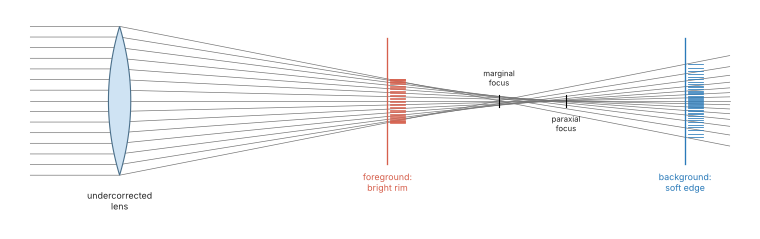

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.0))
sketch.spherical_aberration_bokeh(ax)
plt.show()

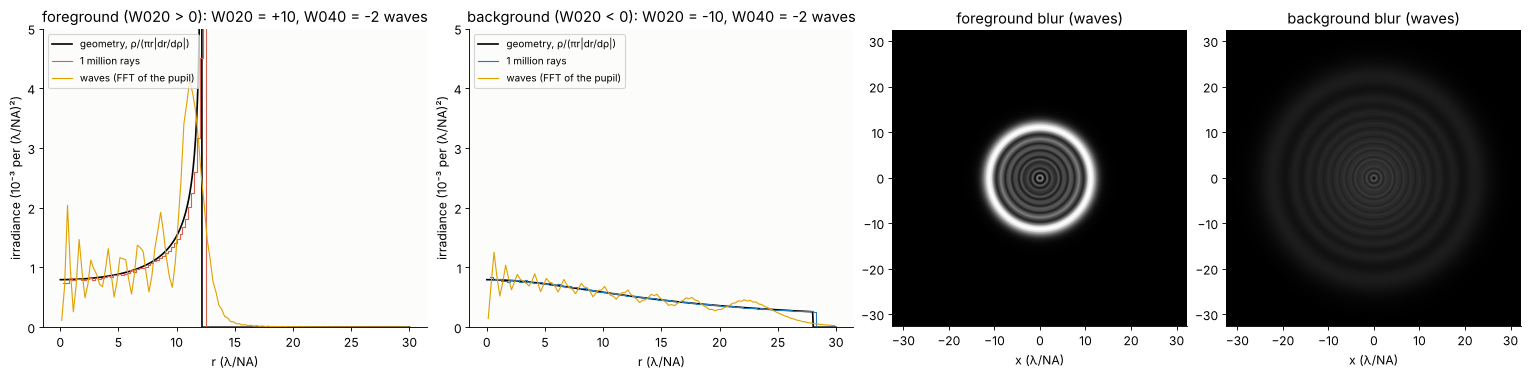

foreground (W020 > 0): rim at r = 12.0, outermost ray at 12.17 λ/NA
background (W020 < 0): rim at r = 28.0, outermost ray at 28.00 λ/NA


In [8]:
W040 = -2.0                                 # undercorrected spherical aberration, waves
cases = [(+10.0, "foreground (W020 > 0)", RED), (-10.0, "background (W020 < 0)", BLUE)]
r = np.linspace(0.01, 30, 600)
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained", width_ratios=[1.3, 1.3, 1, 1])
for a, (W020, name, c) in zip(ax[:2], cases):
    # rays
    rho = np.sqrt(rng.uniform(0, 1, 1_000_000))
    rr = np.abs(2*W020*rho + 4*W040*rho**3)
    edges = np.linspace(0, 30, 121)
    h = np.histogram(rr, edges)[0]/len(rr)/(np.pi*(edges[1:]**2 - edges[:-1]**2))
    # waves
    x, I = ph.defocused_psf(W020, W040, n_pupil=512, n=2048)
    k = len(x)//2
    X, Y = np.meshgrid(x, x)
    R = np.hypot(X, Y)
    wave = np.histogram(R.ravel(), edges, weights=I.ravel())[0]/np.histogram(R.ravel(), edges)[0]
    E = ph.defocus_profile(r, W020, W040)
    a.plot(r, E*1e3, color="k", lw=1.5, label="geometry, ρ/(πr|dr/dρ|)")
    a.step(edges[1:], h*1e3, color=c, where="post", lw=1, label="1 million rays")
    a.plot((edges[1:] + edges[:-1])/2, wave*1e3, color=ORANGE, lw=1, label="waves (FFT of the pupil)")
    a.set_ylim(0, 5)
    a.set_xlabel("r (λ/NA)")
    a.set_ylabel("irradiance (10⁻³ per (λ/NA)²)")
    a.set_title("{}: W020 = {:+.0f}, W040 = {:.0f} waves".format(name, W020, W040))
    a.legend(loc="upper left", fontsize=9)
for a, (W020, name, c) in zip(ax[2:], cases):
    x, I = ph.defocused_psf(W020, W040, n_pupil=512, n=2048)
    k = len(x)//2
    sl = slice(k - 260, k + 260)
    a.imshow(I[sl, sl], extent=[x[k - 260], x[k + 259]]*2, cmap="gray", vmax=0.004)
    a.set_title(name.split(" ")[0] + " blur (waves)")
    a.set_xlabel("x (λ/NA)")
plt.show()
for W020, name, _ in cases:
    rho = np.linspace(0, 1, 100001)
    rr = 2*W020*rho + 4*W040*rho**3
    print("{}: rim at r = {:.1f}, outermost ray at {:.2f} λ/NA".format(name, abs(rr[-1]), np.max(np.abs(rr))))

The geometric profile (black) agrees with a million rays and with the
wave optical blur (the FFT of the pupil, `defocused_psf()`), apart from the
diffraction ripples. In front of the focus, the ring from the caustic
($dr/d\rho = 0$ at $\rho = 0.91$, $r = 12.17$) lies just outside the rim of
the pupil's shadow at $r = 12$: a thin bright edge, the soap bubble. Behind
the focus the irradiance falls by a factor of three from the centre to the
edge.

Now the real lens, wide open and at f/4, focused at 1 m.

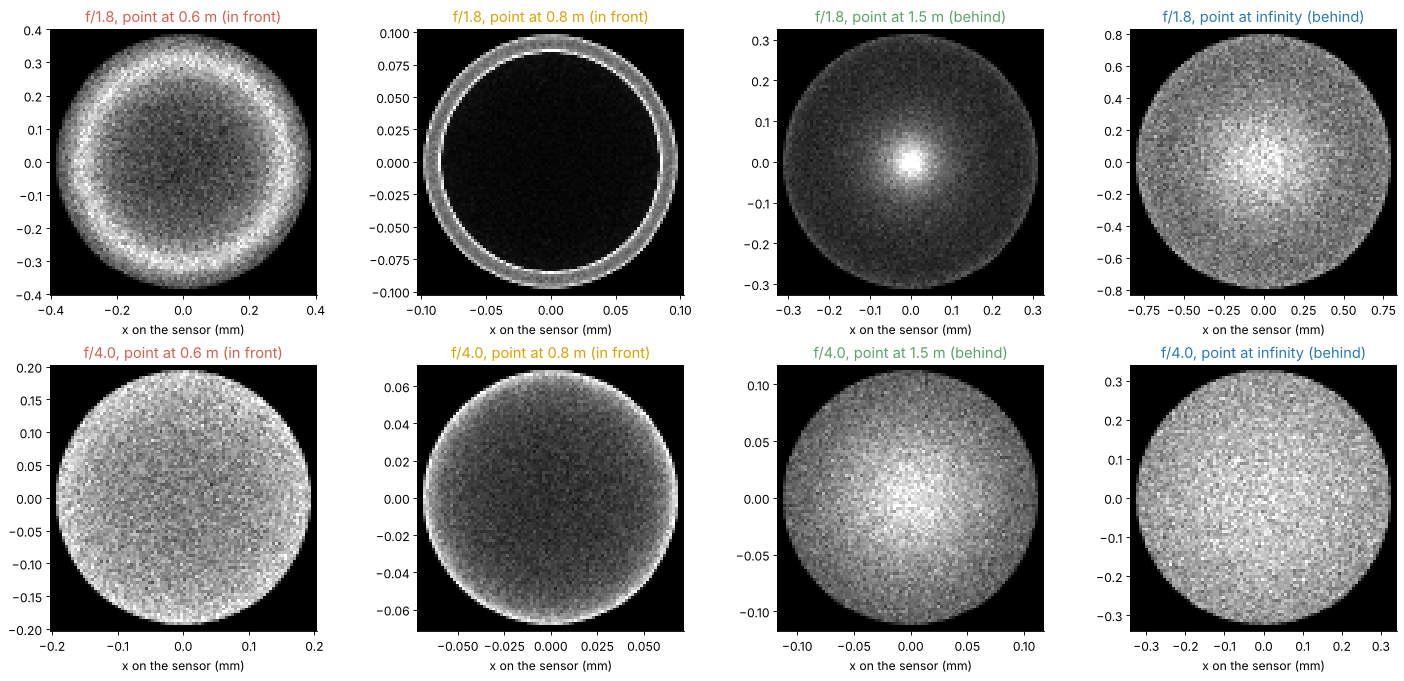

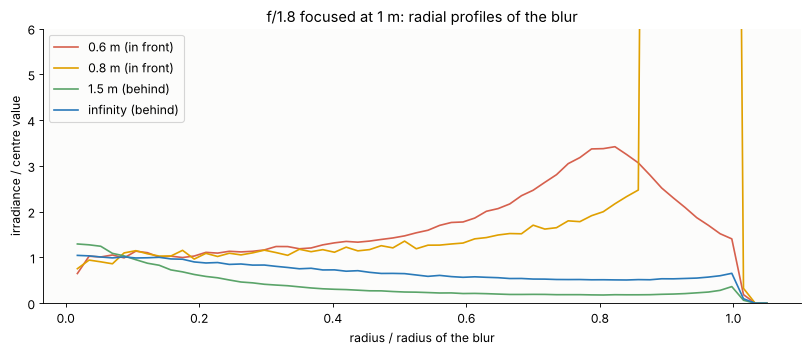

0.6 m (in front)  : blur diameter 0.77 mm, rim/centre 3.42
0.8 m (in front)  : blur diameter 0.20 mm, rim/centre 35.91
1.5 m (behind)    : blur diameter 0.62 mm, rim/centre 0.36
infinity (behind) : blur diameter 1.59 mm, rim/centre 0.65


In [9]:
near = [(600.0, "0.6 m (in front)", RED), (800.0, "0.8 m (in front)", ORANGE),
        (1500.0, "1.5 m (behind)", GREEN), (np.inf, "infinity (behind)", BLUE)]
fig, ax = plt.subplots(2, 4, figsize=(18, 8.4), layout="constrained")
profiles = {}
for j, (d, name, c) in enumerate(near):
    for i, N in enumerate((1.8, 4.0)):
        S = ph.focus(ph.double_gauss(N), 1000.0)
        fp = ph.point_footprint(at_distance(S, d), 0.0, 400_000, rng)
        R = np.hypot(fp.x, fp.y)
        r_max = np.max(R)*1.05
        e = np.linspace(-r_max, r_max, 91)
        E = ph.splat(fp, e, e)
        ax[i, j].imshow(E.T, extent=[e[0], e[-1]]*2, origin="lower", cmap="gray", interpolation="nearest",
                        vmax=np.percentile(E, 99.7))
        ax[i, j].set_title("f/{:.1f}, point at {}".format(N, name), color=c)
        ax[i, j].set_xlabel("x on the sensor (mm)")
        if N == 1.8:
            re = np.linspace(0, r_max, 61)
            h = np.histogram(R, re, weights=fp.weight)[0]/(np.pi*np.diff(re**2))
            profiles[d] = (re, h/np.mean(h[:10]))
plt.show()
fig, ax = plt.subplots(figsize=(10, 4.3), layout="constrained")
for d, name, c in near:
    re, h = profiles[d]
    ax.plot(re[1:]/re[-1]*1.05, h, color=c, label=name)
ax.set_xlabel("radius / radius of the blur")
ax.set_ylabel("irradiance / centre value")
ax.set_ylim(0, 6)
ax.set_title("f/1.8 focused at 1 m: radial profiles of the blur")
ax.legend()
plt.show()
for d, name, c in near:
    re, h = profiles[d]
    print("{:18s}: blur diameter {:.2f} mm, rim/centre {:.2f}".format(name, 2*re[-1]/1.05,
                                                                     np.max(h[-15:])))

In front of the focus (0.6 m and 0.8 m) the f/1.8 blurs have bright
rims, 3.4 times the centre at 0.6 m. At 0.8 m the point is so close to the
focus that the caustic lies inside the blur: a dark core surrounded by a
narrow bright ring and a faint halo, the typical blur of a point just out of
focus. Behind the focus (1.5 m, infinity) the blurs fade towards the edge,
down to 0.36 and 0.65 of the centre. Stopped down to f/4, the spherical
aberration is 16 times smaller ($\propto \rho^4$) and the blurs are nearly
flat disks; the residual bright rim at 0.8 m is the higher order spherical
aberration of the zone that is left.

Bright-rimmed blurs make the background busy, because overlapping rims
draw lines. A thin twig, blurred by a kernel with a bright rim, turns into
two parallel lines, the "nervous" or *nisen* (double line) bokeh. Below,
the same scene of twigs is blurred with the two kernels of the f/1.8 lens,
both drawn at the same size so that only their shape differs.

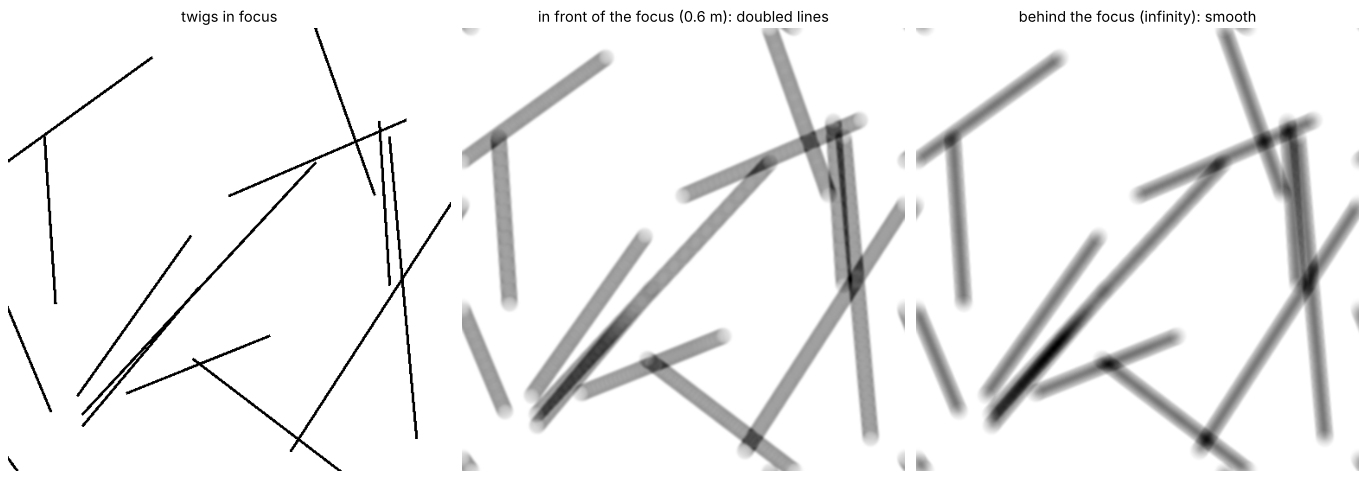

In [10]:
# a scene of thin twigs, blurred with the foreground and the background kernels of f/1.8
n_img = 512
yy, xx = np.mgrid[0:n_img, 0:n_img]/n_img
twigs = np.zeros((n_img, n_img))
rng_t = np.random.default_rng(3)
for _ in range(14):
    x0, y0 = rng_t.uniform(0, 1, 2)
    ang = rng_t.uniform(0, np.pi)
    dist = np.abs((xx - x0)*np.sin(ang) - (yy - y0)*np.cos(ang))
    along = (xx - x0)*np.cos(ang) + (yy - y0)*np.sin(ang)
    twigs += (dist < 0.003)*(np.abs(along) < rng_t.uniform(0.15, 0.4))
twigs = np.clip(twigs, 0, 1)


def kernel(d, N=1.8, n=25):
    """Blur of a point at distance d on a grid of n pixels across 1.2 blur diameters (both blurs
    drawn at the same size, to compare their shapes)."""
    S = ph.focus(ph.double_gauss(N), 1000.0)
    fp = ph.point_footprint(at_distance(S, d), 0.0, 400_000, rng)
    r_max = 0.6*traced_diameter(at_distance(S, d))
    e = np.linspace(-r_max, r_max, n + 1)
    K = ph.splat(fp, e, e)
    return K/K.sum()


def blur(img, K):
    pad = np.zeros_like(img)
    m = K.shape[0]
    pad[:m, :m] = K
    pad = np.roll(pad, (-(m//2), -(m//2)), axis=(0, 1))
    return np.real(np.fft.ifft2(np.fft.fft2(img)*np.fft.fft2(pad)))


K_fore, K_back = kernel(600.0), kernel(np.inf)
fig, ax = plt.subplots(1, 3, figsize=(17, 5.8), layout="constrained")
ax[0].imshow(twigs, cmap="gray_r")
ax[0].set_title("twigs in focus")
ax[1].imshow(blur(twigs, K_fore), cmap="gray_r")
ax[1].set_title("in front of the focus (0.6 m): doubled lines")
ax[2].imshow(blur(twigs, K_back), cmap="gray_r")
ax[2].set_title("behind the focus (infinity): smooth")
for a in ax:
    a.axis("off")
plt.show()

### When does the blur need waves?

The geometric blur is the limit of many waves of defocus. With $W_{020}$
waves of defocus, the blur is $4|W_{020}|$ λ/NA across, and the pupil seen
from the blur has about $|W_{020}|$ Fresnel zones. Below a few waves, the
wave optical image is no longer a disk.

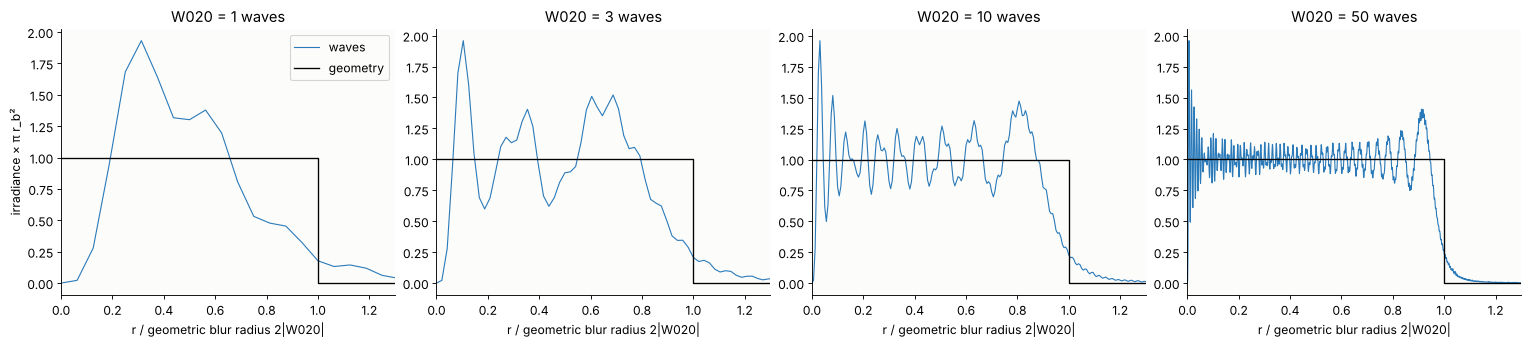

W020 =    1 waves:  16.0 % of the light outside the geometric disk
W020 =    3 waves:   9.2 % of the light outside the geometric disk
W020 =   10 waves:   5.0 % of the light outside the geometric disk
W020 =   50 waves:   2.2 % of the light outside the geometric disk
point at 1.5 m (behind)    : blur radius 0.141 mm = 65 λ/NA, W020 = 32 waves
point at infinity (behind) : blur radius 0.612 mm = 289 λ/NA, W020 = 145 waves


In [11]:
# when is the blur a shadow of the pupil? pure defocus of 1 to 50 waves
W020s = [1.0, 3.0, 10.0, 50.0]
fig, ax = plt.subplots(1, 4, figsize=(19, 4.2), layout="constrained")
dev = []
for a, W020 in zip(ax, W020s):
    n_pupil = 512 if W020 < 40 else 1024
    x, I = ph.defocused_psf(-W020, n_pupil=n_pupil, n=4*n_pupil)
    k = len(x)//2
    r_b = 2*W020
    a.plot(x[k:]/r_b, I[k, k:]*np.pi*r_b**2, color=BLUE, lw=1, label="waves")
    a.plot([0, 1, 1, 1.3], [1, 1, 0, 0], color="k", lw=1.2, label="geometry")
    a.set_xlim(0, 1.3)
    a.set_xlabel("r / geometric blur radius 2|W020|")
    a.set_title("W020 = {:.0f} waves".format(W020))
    X, Y = np.meshgrid(x, x)
    R = np.hypot(X, Y)/r_b
    inside = R < 1
    dev.append(np.sum(I[~inside])*(x[1] - x[0])**2)
ax[0].set_ylabel("irradiance × π r_b²")
ax[0].legend()
plt.show()
for W020, d in zip(W020s, dev):
    print("W020 = {:4.0f} waves: {:5.1f} % of the light outside the geometric disk".format(W020, 100*d))
for d, name, c in near[2:]:
    S = at_distance(S1, d)
    pm = S.paraxial()
    c_d = blur_first_order(S1, d)
    print("point at {:18s}: blur radius {:.3f} mm = {:.0f} λ/NA, W020 = {:.0f} waves".format(
        name, c_d/2, c_d/2*pm.na/WL_D, c_d/4*pm.na/WL_D))

At 1 wave of defocus the image is a blob with most of its light in the
middle; from 10 waves on it is a disk with Fresnel ripples on top and
about 5 % of the light diffracted outside, and at 50 waves 2 %. A point at
infinity seen by the lens focused at 1 m has 145 waves of defocus, and even a
point at 1.5 m has 32. So bokeh is geometric optics, with two exceptions:
points very close to the plane of focus, and fine structure inside the blur,
like the onion rings of section 5.

## 4. The cat's eye

Off the axis, the beam from a point passes the lens obliquely. The stop
still admits a full circle, but the rims of the front and rear elements,
seen from the oblique point, are shifted against the stop in opposite
directions and cut into the beam from the top and from the bottom. The
pupil seen from the point is the intersection of the stop and the shifted
rims, a lens-shaped "cat's eye", and so is the blur on the sensor.

Paraxially, a ray from the object point through the point $h$ of the
entrance pupil plane meets surface $k$ at the height $A_k h + B_k u$, with
its slope $u$. For an object at infinity $u$ is fixed by the field angle, so
the ray passes the clear aperture $a_k$ if $h$ lies in a circle of radius
$a_k/|A_k|$ centred at $-B_k u/A_k$ (`vignetting_circles()`). The
traced rays below (blue) show where the light really passes the entrance
pupil plane, with the paraxial circles of the front group (red), the rear
group (green) and the stop (black). The titles give the traced fraction of
the pupil area and the paraxial one.

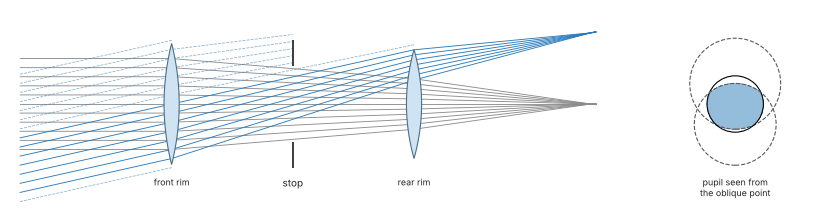

In [12]:
fig, ax = plt.subplots(figsize=(13, 4.2))
sketch.cats_eye_vignetting(ax)
plt.show()

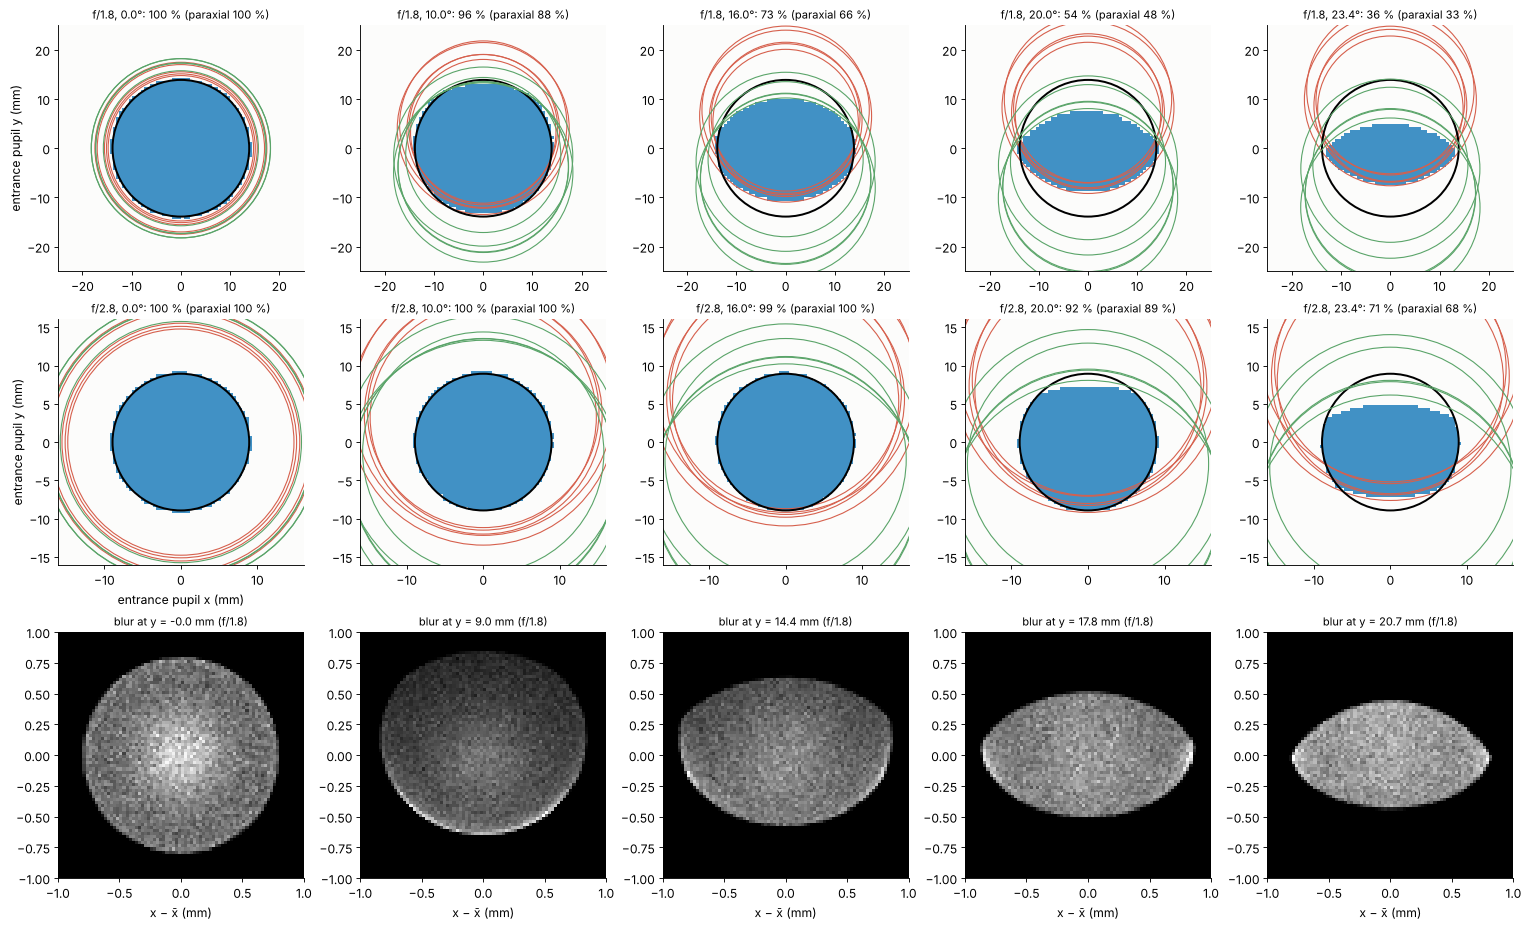

f/1.8, 20°: vignetting circles (paraxial), radius and shift in the entrance pupil plane
  surface  0: radius  17.00 mm, centre shifted by  +9.93 mm
  surface  1: radius  17.47 mm, centre shifted by  +8.28 mm
  surface  2: radius  15.12 mm, centre shifted by  +8.15 mm
  surface  3: radius  15.53 mm, centre shifted by  +7.25 mm
  surface  4: radius  14.78 mm, centre shifted by  +6.76 mm
  surface  5: radius  13.89 mm, centre shifted by  +0.00 mm
  surface  6: radius  15.76 mm, centre shifted by  -2.82 mm
  surface  7: radius  18.19 mm, centre shifted by  -3.50 mm
  surface  8: radius  17.30 mm, centre shifted by  -7.76 mm
  surface  9: radius  17.34 mm, centre shifted by  -7.94 mm
  surface 10: radius  18.22 mm, centre shifted by -10.15 mm


In [13]:
S_inf = {N: rt.System(ph.focus(ph.double_gauss(N), 1000.0).surfaces, 5, WL_D,
                     field_angle=np.deg2rad(23.4)) for N in (1.8, 2.8, 4.0)}
angles = [0.0, 10.0, 16.0, 20.0, 23.4]
fig, ax = plt.subplots(3, 5, figsize=(19, 11.5), layout="constrained")
for i, N in enumerate((1.8, 2.8)):
    S = S_inf[N]
    ep_r = S.paraxial().ep_radius
    for j, deg in enumerate(angles):
        a = ax[i, j]
        th = np.deg2rad(deg)
        fp = ph.point_footprint(S, th, 30000, rng)
        box = np.linspace(-1.8*ep_r, 1.8*ep_r, 81)
        H = np.histogram2d(fp.pupil_x, fp.pupil_y, [box, box])[0] > 0
        a.imshow(np.where(H.T, 1.0, np.nan), extent=[box[0], box[-1]]*2, origin="lower",
                 cmap="Blues", vmin=0, vmax=1.6, interpolation="nearest")
        cen, rad, idx = ph.vignetting_circles(S, th)
        frac = ph.vignetted_fraction(cen, rad, ep_r)[0]
        for c, r, k in zip(cen, rad, idx):
            if r < 3*ep_r:
                a.add_patch(plt.Circle(c, r, fill=False, lw=1 if k != 5 else 1.8,
                                       color="k" if k == 5 else (RED if k < 5 else GREEN)))
        a.set_xlim(-1.8*ep_r, 1.8*ep_r)
        a.set_ylim(-1.8*ep_r, 1.8*ep_r)
        a.set_aspect("equal")
        a.set_title("f/{:.1f}, {:.1f}°: {:.0f} % (paraxial {:.0f} %)".format(
            N, deg, 100*np.sum(fp.weight)/(np.pi*ep_r**2*np.cos(th)), 100*frac), fontsize=10)
        if j == 0:
            a.set_ylabel("entrance pupil y (mm)")
    # the blurs on the sensor at f/1.8
S = S_inf[1.8]
for j, deg in enumerate(angles):
    fp = ph.point_footprint(S, np.deg2rad(deg), 200_000, rng)
    cx, cy = np.average(fp.x, weights=fp.weight), np.average(fp.y, weights=fp.weight)
    e = np.linspace(-1.0, 1.0, 81)
    E = ph.splat(fp, cx + e, cy + e)
    ax[2, j].imshow(E.T, extent=[e[0], e[-1]]*2, origin="lower", cmap="gray", interpolation="nearest")
    ax[2, j].set_title("blur at y = {:.1f} mm (f/1.8)".format(cy), fontsize=10)
    ax[2, j].set_xlabel("x − x̄ (mm)")
ax[1, 0].set_xlabel("entrance pupil x (mm)")
plt.show()
cen, rad, idx = ph.vignetting_circles(S_inf[1.8], np.deg2rad(20.0))
print("f/1.8, 20°: vignetting circles (paraxial), radius and shift in the entrance pupil plane")
for c, r, k in zip(cen, rad, idx):
    print("  surface {:2d}: radius {:6.2f} mm, centre shifted by {:+6.2f} mm".format(k, r, c[1]))

On the axis the stop limits the beam. At 10° the bottom of the pupil
is clipped by the front group (red circles) and the top by the rear group
(green circles); at 20° only 54 % of the pupil is left, and at the corner of
the frame (23.4°) 36 %. The paraxial circles predict the shape and the
direction of the cuts, but they underestimate the light by 3 to 8 points:
the real rays bend more than the paraxial ones near the rims (pupil
aberrations). At f/2.8 the stop is smaller than the cut, and the blurs
stay round up to 16°.

The cat's eyes are oriented along the circles around the centre of the
image, which gives a swirly look to the background of fast lenses (more
pronounced in the Petzval lenses with a long distance between the groups).
The blurs on the sensor (bottom) also show that the bright rim of the
spherical aberration becomes one-sided off the axis.

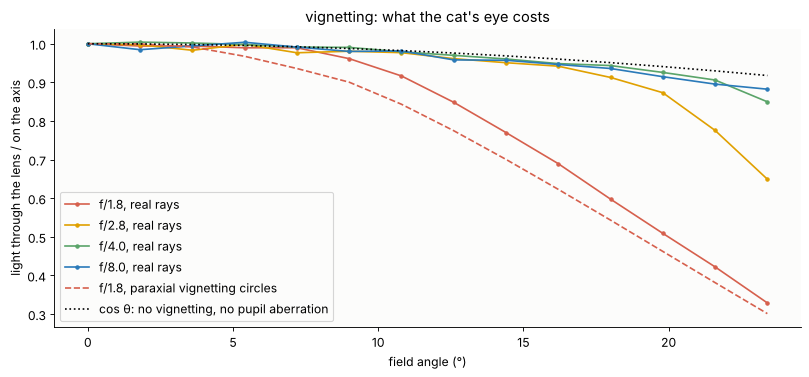

light at 20° relative to the axis: f/1.8 0.50, f/2.8 0.86, f/4.0 0.92, f/8.0 0.91


In [14]:
fields_deg = np.linspace(0, 23.4, 14)[1:]
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
ri = {}
for N, c in ((1.8, RED), (2.8, ORANGE), (4.0, GREEN), (8.0, BLUE)):
    S = rt.System(ph.focus(ph.double_gauss(N), 1000.0).surfaces, 5, WL_D, field_angle=0.4)
    ri[N] = ph.relative_illumination(S, np.deg2rad(fields_deg), 20000, rng)
    ax.plot(np.r_[0, fields_deg], np.r_[1, ri[N]], "o-", ms=3, color=c, label="f/{:.1f}, real rays".format(N))
S = S_inf[1.8]
ep_r = S.paraxial().ep_radius
par = [ph.vignetted_fraction(*ph.vignetting_circles(S, np.deg2rad(d))[:2], ep_r)[0]*np.cos(np.deg2rad(d))
       for d in fields_deg]
ax.plot(np.r_[0, fields_deg], np.r_[1, par], "--", color=RED, label="f/1.8, paraxial vignetting circles")
ax.plot(np.r_[0, fields_deg], np.cos(np.deg2rad(np.r_[0, fields_deg])), ":", color="k",
        label="cos θ: no vignetting, no pupil aberration")
ax.set_xlabel("field angle (°)")
ax.set_ylabel("light through the lens / on the axis")
ax.set_title("vignetting: what the cat's eye costs")
ax.legend()
plt.show()
print("light at 20° relative to the axis: " + ", ".join("f/{:.1f} {:.2f}".format(N, np.interp(20, fields_deg, v))
                                                       for N, v in ri.items()))

The cat's eye is also the main cause of the dark corners of fast lenses.
At f/1.8 the light from 20° is half of that on the axis, at f/2.8 86 %. From
f/4 on there is no vignetting left and the light falls only slightly faster
than $\cos\theta$, the projection of the pupil plane: the real entrance pupil
of an oblique beam is a little smaller than the paraxial one here. The image
side adds the usual $\cos^3$ (larger image areas towards the corners of a
distortion-free lens), together the $\cos^4$ law.

## 5. Onion rings

Many modern lenses contain aspheres, moulded in glass or plastic. The moulds
are diamond turned and polished, which leaves small ripples of the surface
with periods of tenths of a millimetre to millimetres and amplitudes of a
few tens of nanometres. In focus they hardly matter. In the blur of a
bright point they show up as concentric rings, the "onion rings" of
photographers.

A ripple of the wavefront $W = A\cos(2\pi\rho/p)$ (period $p$ in units of
the pupil radius) tilts the rays by $dW/d\rho$, which shifts them in the
blur by $A\,2\pi/p$ λ/NA, alternately inwards and outwards. The local
density of the rays changes by the relative amount
$-(d^2W/d\rho^2)/(dr/d\rho)$, the transport of intensity equation (TIE) for
rays. With $dr/d\rho = 2W_{020}$ the ring contrast is

$$\text{rays: } \frac{2\pi^2 A}{|W_{020}|\,p^2},$$

which grows towards the focus. In waves, the ripple is a weak phase grating
whose orders $\pm 1$ get out of step with the zero order as the light
propagates (Talbot effect). A converging beam that travels to a sensor
$|\Delta|$ from its focus is equivalent to a collimated beam travelling
$z_{\mathrm{eff}} \approx R^2/|\Delta|$ (Fresnel scaling,
`converging_beam_equivalent()`), and in pupil units the phase lag of the
orders is $\pi\lambda z_{\mathrm{eff}}/p^2 = \pi/(2|W_{020}|p^2)$, so

$$\text{waves: } 2(2\pi A)\left|\sin\frac{\pi}{2|W_{020}|\,p^2}\right|$$

(`onion_ring_contrast()`), which is the ray result for small arguments and
stays below $4\pi A$. A ripple of 0.03 waves with ten periods across the
pupil radius, for a range of defoci:

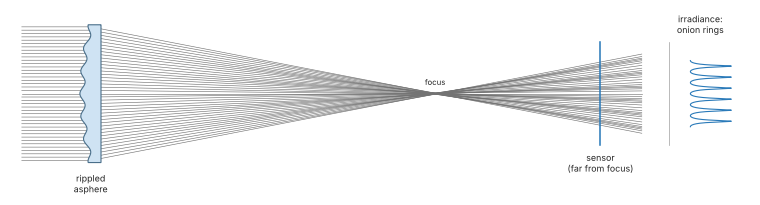

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.0))
sketch.rippled_asphere(ax)
plt.show()

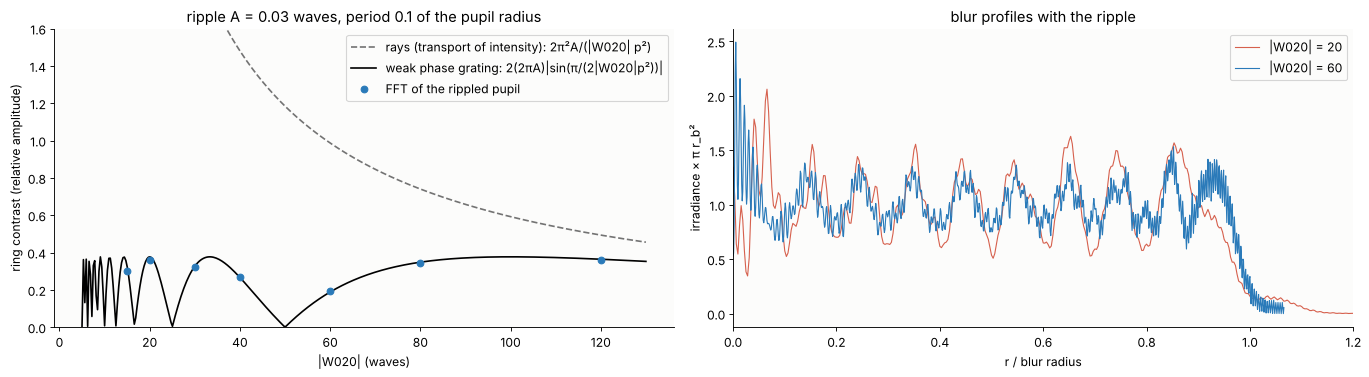

|W020| =  15: Talbot phase 10.47 rad, contrast FFT 0.301, grating formula 0.326, rays 3.948
|W020| =  20: Talbot phase 7.85 rad, contrast FFT 0.359, grating formula 0.377, rays 2.961
|W020| =  30: Talbot phase 5.24 rad, contrast FFT 0.322, grating formula 0.326, rays 1.974
|W020| =  40: Talbot phase 3.93 rad, contrast FFT 0.270, grating formula 0.267, rays 1.480
|W020| =  60: Talbot phase 2.62 rad, contrast FFT 0.191, grating formula 0.188, rays 0.987
|W020| =  80: Talbot phase 1.96 rad, contrast FFT 0.342, grating formula 0.348, rays 0.740
|W020| = 120: Talbot phase 1.31 rad, contrast FFT 0.359, grating formula 0.364, rays 0.493


In [16]:
# a weak ripple in the pupil, A = 0.03 waves, 10 periods across the radius
A_w, period = 0.03, 0.1
W020s = np.array([15, 20, 30, 40, 60, 80, 120])
measured = []
for W020 in W020s:
    n_pupil = 512 if W020 <= 60 else 1024
    ripple = lambda rho: A_w*np.cos(2*np.pi*rho/period)
    x, I = ph.defocused_psf(-W020, wavefront=ripple, n_pupil=n_pupil, n=4*n_pupil)
    _, I0 = ph.defocused_psf(-W020, n_pupil=n_pupil, n=4*n_pupil)
    k = len(x)//2
    rel = I[k, k:]/I0[k, k:] - 1
    m = (x[k:] > 0.3*2*W020) & (x[k:] < 0.7*2*W020)
    measured.append(np.sqrt(2)*np.std(rel[m]))
measured = np.array(measured)
WW = np.linspace(5, 130, 400)
theta = np.pi/(2*WW*period**2)               # Talbot phase pi lambda z_eff/p^2 in pupil units
wave = 2*(2*np.pi*A_w)*np.abs(np.sin(theta))
rays = 2*(2*np.pi*A_w)*theta
fig, ax = plt.subplots(1, 2, figsize=(17, 4.6), layout="constrained")
ax[0].plot(WW, rays, "--", color=GREY, label="rays (transport of intensity): 2π²A/(|W020| p²)")
ax[0].plot(WW, wave, color="k", label="weak phase grating: 2(2πA)|sin(π/(2|W020|p²))|")
ax[0].plot(W020s, measured, "o", color=BLUE, label="FFT of the rippled pupil")
ax[0].set_ylim(0, 1.6)
ax[0].set_xlabel("|W020| (waves)")
ax[0].set_ylabel("ring contrast (relative amplitude)")
ax[0].set_title("ripple A = {:.2f} waves, period {:.1f} of the pupil radius".format(A_w, period))
ax[0].legend()
for W020, c in ((20, RED), (60, BLUE)):
    x, I = ph.defocused_psf(-W020, wavefront=lambda rho: A_w*np.cos(2*np.pi*rho/period), n_pupil=512, n=2048)
    k = len(x)//2
    ax[1].plot(x[k:]/(2*W020), I[k, k:]*np.pi*(2*W020)**2, color=c, lw=1, label="|W020| = {}".format(W020))
ax[1].set_xlim(0, 1.2)
ax[1].set_xlabel("r / blur radius")
ax[1].set_ylabel("irradiance × π r_b²")
ax[1].set_title("blur profiles with the ripple")
ax[1].legend()
plt.show()
for W020, mm in zip(W020s, measured):
    th = np.pi/(2*W020*period**2)
    print("|W020| = {:3d}: Talbot phase {:4.2f} rad, contrast FFT {:.3f}, grating formula {:.3f}, rays {:.3f}".format(
        W020, th, mm, 4*np.pi*A_w*abs(np.sin(th)), 4*np.pi*A_w*th))

The FFT of the rippled pupil follows the grating formula within 8 % (the
largest deviation at $|W_{020}| = 15$, where the orders are already
displaced by a sizeable part of the blur). The rays are right only for large defocus, where the
Talbot phase is below one: from 80 waves on they overestimate the contrast
by a factor of two at 80 waves and 35 % at 120, near the focus by an order
of magnitude. Near
the focus the rings even vanish where the phase lag is a multiple of π (at
$|W_{020}| = 25$ and 50 here) and come back.

Now the real lens, with a ripple of 25 nm amplitude and 1 mm period on
surface 6 (the first surface behind the stop, the front of the rear doublet),
traced with `RippledSurface`.

ripple: 25 nm, OPD amplitude 0.029 waves, 9.68 periods across the pupil radius


point at 3 m: |W020| = 87 waves paraxially, 136 waves locally (with the spherical aberration), ripple period 0.1021 of the pupil; Talbot phase 1.11 rad
    ring contrast: traced 0.43, rays (formula) 0.40, waves (formula) 0.32


point at infinity: |W020| = 145 waves paraxially, 194 waves locally (with the spherical aberration), ripple period 0.1023 of the pupil; Talbot phase 0.77 rad
    ring contrast: traced 0.30, rays (formula) 0.28, waves (formula) 0.25


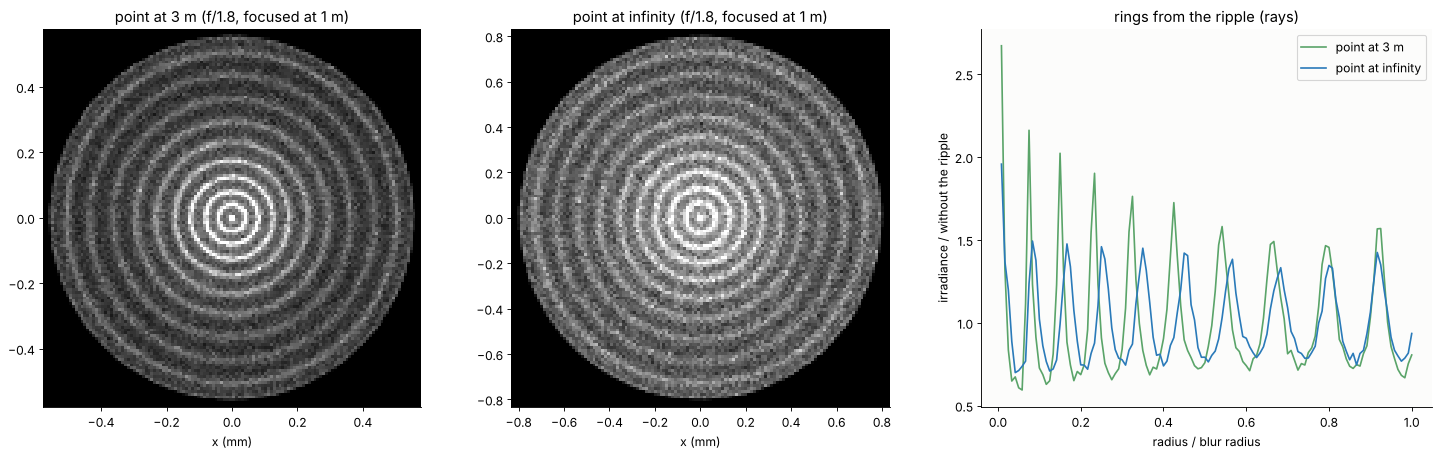

In [17]:
# the double Gauss with a ripple on surface 6, the first one behind the stop
a_rip, p_rip = 25e-6, 1.0                                # mm: 25 nm amplitude, 1 mm period
base = ph.focus(ph.double_gauss(1.8), 1000.0)
s6 = base.surfaces[6]
rippled = ph.RippledSurface(s6.R, s6.thickness, amplitude=a_rip, period=p_rip,
                            material=s6.material, semi_diameter=s6.semi_diameter)
S_rip = rt.System(base.surfaces[:6] + [rippled] + base.surfaces[7:], 5, WL_D, object_distance=1000.0,
                  object_height=1.0)
S_rip.surfaces[-1].thickness = base.surfaces[-1].thickness
n6 = s6.index(WL_D*1e6, 1.0)
A_rip = (n6 - 1.0)*a_rip/WL_D                            # waves
y6 = base.paraxial().marginal[6, 0]                     # marginal ray height on surface 6
period_pupil = p_rip/y6
print("ripple: {:.0f} nm, OPD amplitude {:.3f} waves, {:.2f} periods across the pupil radius".format(
    a_rip*1e6, A_rip, 1/period_pupil))
fig, ax = plt.subplots(1, 3, figsize=(18, 5.6), layout="constrained")
for a, d in zip(ax, (3000.0, np.inf)):
    S = at_distance(S_rip, d)
    S_clean = at_distance(base, d)
    fp = ph.point_footprint(S, 0.0, 600_000, rng)
    fp0 = ph.point_footprint(S_clean, 0.0, 600_000, rng)
    rb = np.max(np.hypot(fp0.x, fp0.y))
    e = np.linspace(-1.05*rb, 1.05*rb, 131)
    E = ph.splat(fp, e, e)
    a.imshow(E.T, extent=[e[0], e[-1]]*2, origin="lower", cmap="gray", interpolation="nearest", vmax=np.percentile(E, 99.5))
    a.set_title("point at {} (f/1.8, focused at 1 m)".format("3 m" if np.isfinite(d) else "infinity"))
    a.set_xlabel("x (mm)")
    # ring contrast from the rays
    re = np.linspace(0, rb, 121)
    h = np.histogram(np.hypot(fp.x, fp.y), re, weights=fp.weight)[0]
    h0 = np.histogram(np.hypot(fp0.x, fp0.y), re, weights=fp0.weight)[0]
    rel = h/h0 - 1
    m = (re[1:] > 0.3*rb) & (re[1:] < 0.7*rb)
    traced = np.sqrt(2)*np.std(rel[m])
    # the local scales from the rays: blur radius and height on surface 6 against the stop radius
    rho = np.hypot(fp0.stop_x, fp0.stop_y)
    mid = (rho > 0.3) & (rho < 0.7)
    dr_drho = np.polyfit(rho[mid], np.hypot(fp0.x, fp0.y)[mid], 1)[0]
    b6 = S_clean.trace(ph._launch(S_clean, 0.0, fp0.pupil_x, fp0.pupil_y)[0])
    r6 = np.hypot(b6.points[7][:, 0], b6.points[7][:, 1])[b6.valid]
    dr6_drho = np.polyfit(rho[mid], r6[mid], 1)[0]
    pm = S_clean.paraxial()
    c_d = blur_first_order(base, d)
    W020_par = c_d/4*pm.na/WL_D
    W020 = dr_drho/2*pm.na/WL_D                        # local defocus in the middle zone
    per = p_rip/dr6_drho
    th = np.pi/(2*W020*per**2)
    print("point at {}: |W020| = {:.0f} waves paraxially, {:.0f} waves locally (with the spherical "
          "aberration), ripple period {:.4f} of the pupil; Talbot phase {:.2f} rad".format(
          "3 m" if np.isfinite(d) else "infinity", W020_par, W020, per, th))
    print("    ring contrast: traced {:.2f}, rays (formula) {:.2f}, waves (formula) {:.2f}".format(
          traced, 4*np.pi*A_rip*th, 4*np.pi*A_rip*abs(np.sin(th))))
    ax[2].plot(re[1:]/rb, h/h0, color=BLUE if np.isinf(d) else GREEN,
               label="point at {}".format("3 m" if np.isfinite(d) else "infinity"))
ax[2].set_xlabel("radius / blur radius")
ax[2].set_ylabel("irradiance / without the ripple")
ax[2].set_title("rings from the ripple (rays)")
ax[2].legend()
plt.show()

Ten rings across the blur, one per period of the ripple, with a
contrast of 0.3 to 0.4 from 25 nm of surface error. For the comparison with
the ray formula, the local defocus has to include the spherical aberration:
the blur spreads faster with $\rho$ than first order says (136 instead of
87 waves for the point at 3 m), which lowers the ray contrast. With the
local defocus and the ripple period mapped from surface 6 to the stop, the
traced contrast is within 8 % of the ray formula. The wave formula gives
20 % and 11 % less: the real rings are a little weaker than the ray trace
says, since the Talbot phase is close to one.

In focus, the ripple is a weak phase grating and costs little.

In [18]:
# and in focus? the ripple's diffraction orders are a faint halo
st = 2*np.pi*A_rip                         # phase amplitude
print("Strehl ratio of the ripple alone: J0(2πA)² = {:.4f}; {:.2f} % of the light in the ±1 orders".format(
    np.i0(0)*0 + (1 - st**2/4)**2, 100*st**2/2))
print("the orders land at ±λ/(period in the exit pupil)/NA = ±{:.1f} λ/NA from the image, "
      "a ring of {:.0f} µm radius".format(1/period_pupil, 1/period_pupil*WL_D/0.2778*1e3))

Strehl ratio of the ripple alone: J0(2πA)² = 0.9839; 1.62 % of the light in the ±1 orders
the orders land at ±λ/(period in the exit pupil)/NA = ±9.7 λ/NA from the image, a ring of 20 µm radius


## 6. Apodization: smooth trans focus

The blur of a point is a shadow of the pupil, so a pupil whose transmission
falls smoothly towards the rim gives a blur with soft edges. The Minolta
(now Sony) "Smooth Trans Focus" lenses and Fujifilm's APD lenses put a
radially graded neutral density filter next to the stop for this. Its price
is light: a lens of F-number N whose pupil transmits the mean intensity
fraction τ passes as much light as a clear lens of the T-number

$$T = \frac{N}{\sqrt{\tau}}$$

(`t_number()`); the 135 mm STF lenses are f/2.8 and T4.5. A Gaussian
apodizer $T(\rho) = \exp(-\rho^2/s^2)$ has
$\tau = s^2(1 - e^{-1/s^2})$ (`apodizer_mean_transmission()`), and
`apodizer_for_t_number()` solves for $s$. In the ray trace, each ray gets
the transmission at the place where it passes the stop.

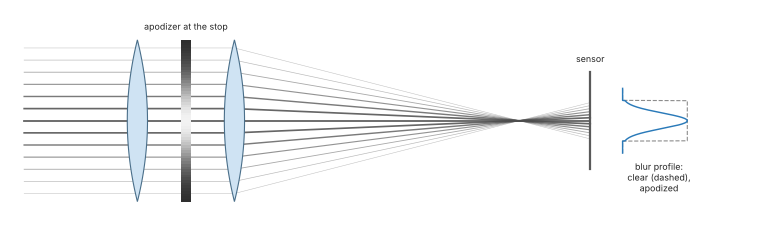

In [19]:
fig, ax = plt.subplots(figsize=(12, 4.0))
sketch.apodized_lens(ax)
plt.show()

f/2.8 with T4.5: Gaussian apodizer with 1/e radius 0.655 of the pupil, mean transmission 0.387, rim 0.097


traced through the double Gauss with the apodizer at the stop: transmission 0.382, T-number 4.53


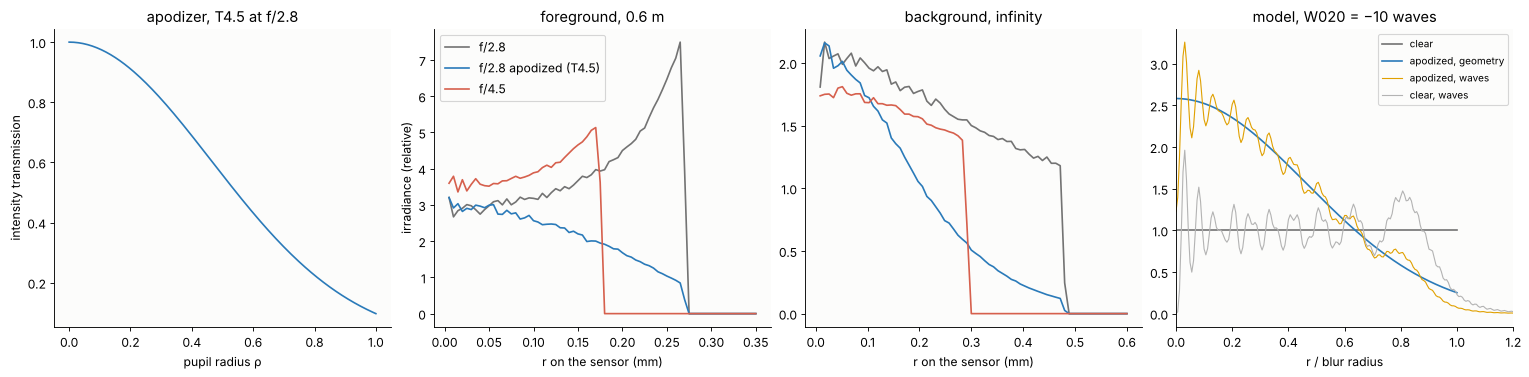

In [20]:
N_A, T_A = 2.8, 4.5
s_A = ph.apodizer_for_t_number(N_A, T_A)
T = ph.gaussian_apodizer(s_A)
tau = ph.apodizer_mean_transmission(s_A)
print("f/2.8 with T4.5: Gaussian apodizer with 1/e radius {:.3f} of the pupil, mean transmission {:.3f}, "
      "rim {:.3f}".format(s_A, tau, T(1.0)))
S28 = ph.focus(ph.double_gauss(N_A), 1000.0)
S45 = ph.focus(ph.double_gauss(T_A), 1000.0)
P_clear = ph.point_footprint(at_distance(S28, 1e9), 0.0, 200_000, rng).weight.sum()
P_apod = ph.point_footprint(at_distance(S28, 1e9), 0.0, 200_000, rng, apodization=T).weight.sum()
print("traced through the double Gauss with the apodizer at the stop: transmission {:.3f}, "
      "T-number {:.2f}".format(P_apod/P_clear, ph.t_number(N_A, P_apod/P_clear)))
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6), layout="constrained")
rr = np.linspace(0, 1, 200)
ax[0].plot(rr, T(rr), color=BLUE)
ax[0].set_xlabel("pupil radius ρ")
ax[0].set_ylabel("intensity transmission")
ax[0].set_title("apodizer, T4.5 at f/2.8")
for a, d, name in ((ax[1], 600.0, "foreground, 0.6 m"), (ax[2], np.inf, "background, infinity")):
    for S, apo, c, lab in ((S28, None, GREY, "f/2.8"), (S28, T, BLUE, "f/2.8 apodized (T4.5)"),
                           (S45, None, RED, "f/4.5")):
        fp = ph.point_footprint(at_distance(S, d), 0.0, 400_000, rng, apodization=apo)
        R = np.hypot(fp.x, fp.y)
        re = np.linspace(0, 0.6 if np.isinf(d) else 0.35, 71)
        h = np.histogram(R, re, weights=fp.weight)[0]/(np.pi*np.diff(re**2))
        a.plot(re[1:], h/P_clear, color=c, label=lab)
    a.set_xlabel("r on the sensor (mm)")
    a.set_title(name)
ax[1].set_ylabel("irradiance (relative)")
ax[1].legend()
# geometric profile of the model (pure defocus) against the traced shape
r = np.linspace(0.005, 0.999, 200)
ax[3].plot(r, ph.defocus_profile(r*20, -10.0)*np.pi*400, color=GREY, label="clear")
ax[3].plot(r, ph.defocus_profile(r*20, -10.0, apodization=T)*np.pi*400, color=BLUE, label="apodized, geometry")
x, I = ph.defocused_psf(-10.0, amplitude=lambda rho: np.sqrt(T(rho)))
k = len(x)//2
ax[3].plot(x[k:]/20, I[k, k:]*np.pi*400, color=ORANGE, lw=1, label="apodized, waves")
x, I = ph.defocused_psf(-10.0)
ax[3].plot(x[k:]/20, I[k, k:]*np.pi*400, color="0.7", lw=1, label="clear, waves")
ax[3].set_xlim(0, 1.2)
ax[3].set_xlabel("r / blur radius")
ax[3].set_title("model, W020 = −10 waves")
ax[3].legend(fontsize=9)
plt.show()

A Gaussian of 1/e radius 0.655 makes an f/2.8 lens T4.5: it transmits
38.7 % of the light, and 9.7 % at the rim. Traced through the double Gauss,
with the filter at the stop, the transmission is 38.2 % (T4.53). The blurs
of the apodized lens are bell-shaped in front of and behind the focus:
the bright rim of the foreground is gone, since the rays that pile up there
come from the rim of the pupil, which the filter darkens. A clear lens
stopped down to f/4.5 passes the same light but gives a smaller disk with a
hard edge. In the model (right), geometry and waves agree for the apodized
pupil, and the diffraction ripples of the clear pupil are suppressed too.

In focus, the apodized pupil keeps the cutoff frequency of f/2.8 but
weights it differently.

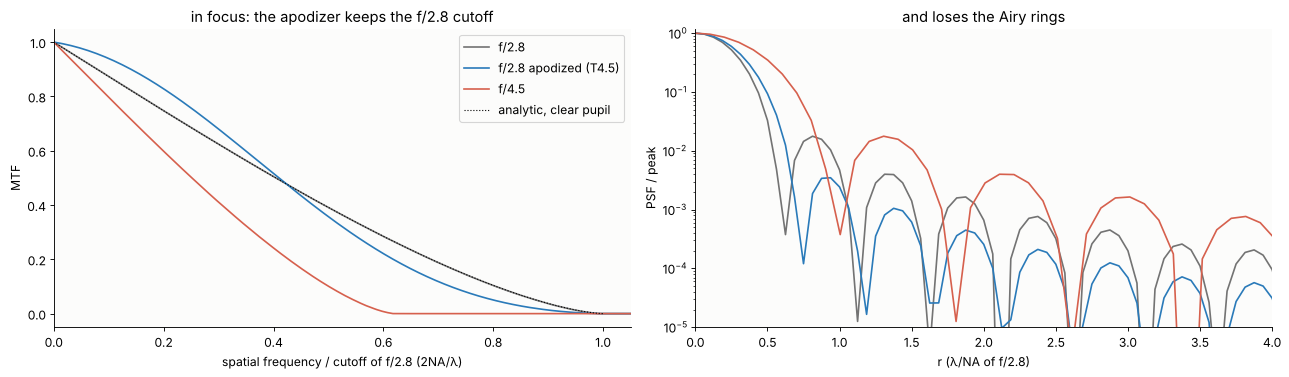

f/2.8          : MTF at 0.2 / 0.4 of the f/2.8 cutoff: 0.747 / 0.505; first ring 1.8e-02 of the peak
f/2.8 apodized : MTF at 0.2 / 0.4 of the f/2.8 cutoff: 0.828 / 0.516; first ring 3.5e-03 of the peak
f/4.5          : MTF at 0.2 / 0.4 of the f/2.8 cutoff: 0.598 / 0.242; first ring 1.8e-02 of the peak


In [21]:
# in focus: diffraction-limited PSF and MTF of the three pupils (scalar model)
def mtf_of(amplitude, scale):
    """MTF of a pupil of radius scale (1: f/2.8) against the frequency in units of the f/2.8 cutoff."""
    x, I = ph.defocused_psf(0.0, amplitude=amplitude, n_pupil=128, n=1024)
    otf = np.abs(np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(I))))
    k = len(x)//2
    nu = (np.arange(len(x)) - k)/(len(x)*(x[1] - x[0]))/2        # in units of the cutoff 2 NA/λ
    return nu[k:]*scale, otf[k, k:]/otf[k, k], x, I


fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained")
for amp, scale, c, lab in ((None, 1.0, GREY, "f/2.8"), (lambda rho: np.sqrt(T(rho)), 1.0, BLUE, "f/2.8 apodized (T4.5)"),
                           (None, N_A/T_A, RED, "f/4.5")):
    nu, mtf, x, I = mtf_of(amp, scale)
    ax[0].plot(nu, mtf, color=c, label=lab)
    k = len(x)//2
    ax[1].semilogy(x[k:]/scale, I[k, k:]/I[k, k], color=c, label=lab)
nu = np.linspace(0, 1, 200)
ax[0].plot(nu, 2/np.pi*(np.arccos(nu) - nu*np.sqrt(1 - nu**2)), "k:", lw=1, label="analytic, clear pupil")
ax[0].set_xlim(0, 1.05)
ax[0].set_xlabel("spatial frequency / cutoff of f/2.8 (2NA/λ)")
ax[0].set_ylabel("MTF")
ax[0].set_title("in focus: the apodizer keeps the f/2.8 cutoff")
ax[0].legend()
ax[1].set_xlim(0, 4)
ax[1].set_ylim(1e-5, 1.2)
ax[1].set_xlabel("r (λ/NA of f/2.8)")
ax[1].set_ylabel("PSF / peak")
ax[1].set_title("and loses the Airy rings")
plt.show()
for amp, scale, lab in ((None, 1.0, "f/2.8"), (lambda rho: np.sqrt(T(rho)), 1.0, "f/2.8 apodized"), (None, N_A/T_A, "f/4.5")):
    nu, mtf, x, I = mtf_of(amp, scale)
    k = len(x)//2
    cut = I[k, k:]/I[k, k]
    j = np.argmax(np.diff(cut) > 0)               # first minimum
    print("{:15s}: MTF at 0.2 / 0.4 of the f/2.8 cutoff: {:.3f} / {:.3f}; first ring {:.1e} of the peak".format(
        lab, np.interp(0.2, nu, mtf), np.interp(0.4, nu, mtf), np.max(cut[j:j + 40])))

The apodized lens has a higher MTF than the clear f/2.8 lens at low
frequencies (0.83 against 0.75 at a fifth of the cutoff) and a lower one
at high frequencies, and its point image has weaker Airy rings: the
first ring has 0.35 % of the peak, five times less than the 1.75 % of the
Airy pattern of the clear pupil (which the FFT reproduces). Compared with the clear f/4.5 lens, which
passes the same light, it is much sharper (MTF 0.52 against 0.24 at 0.4 of
the f/2.8 cutoff). That is the trade of the STF lens: the depth of field and
blur size of f/2.8, the exposure of f/4.5, a sharpness in between, and a
background with soft edges.

## 7. A night scene

Now everything together: a grid of point lights at infinity across the
frame (fairy lights in the far background), the lens focused at 1 m on a
subject that is left out of the picture. Each light is traced with 60,000
rays through the whole aperture, with the vignetting of all clear apertures,
at the C, d and F lines for the red, green and blue channels. Each panel is
exposed for the light in the centre.

In [22]:
# a night scene: fairy lights at infinity across the frame, the lens focused at 1 m
f_w = 50.0
hx, hy = np.linspace(-16, 16, 7), np.linspace(-10, 10, 5)
lights = [(x, y) for x in hx for y in hy]
xe, ye = np.linspace(-18, 18, 601), np.linspace(-12, 12, 401)
wavelengths = (WL_C, WL_D, WL_F)                      # R, G, B
renders = {}
t0 = time.time()
for key, N, apo in (("f/1.8", 1.8, None), ("f/2.8", 2.8, None), ("f/4", 4.0, None),
                    ("f/2.8 apodized (T4.5)", 2.8, T)):
    base = ph.focus(ph.double_gauss(N), 1000.0)
    rgb = []
    for w in wavelengths:
        S = rt.System(base.surfaces, 5, w, field_angle=0.4)
        S.surfaces[-1].thickness = base.surfaces[-1].thickness
        fps = [ph.point_footprint(S, (np.arctan(x/f_w), np.arctan(y/f_w)), 60000, rng, apodization=apo)
               for x, y in lights]
        rgb.append(ph.splat(fps, xe, ye).T)
    renders[key] = np.stack(rgb, axis=-1)
print("rendered {} lights x 3 wavelengths x 4 settings in {:.0f} s".format(len(lights), time.time() - t0))

rendered 35 lights x 3 wavelengths x 4 settings in 19 s


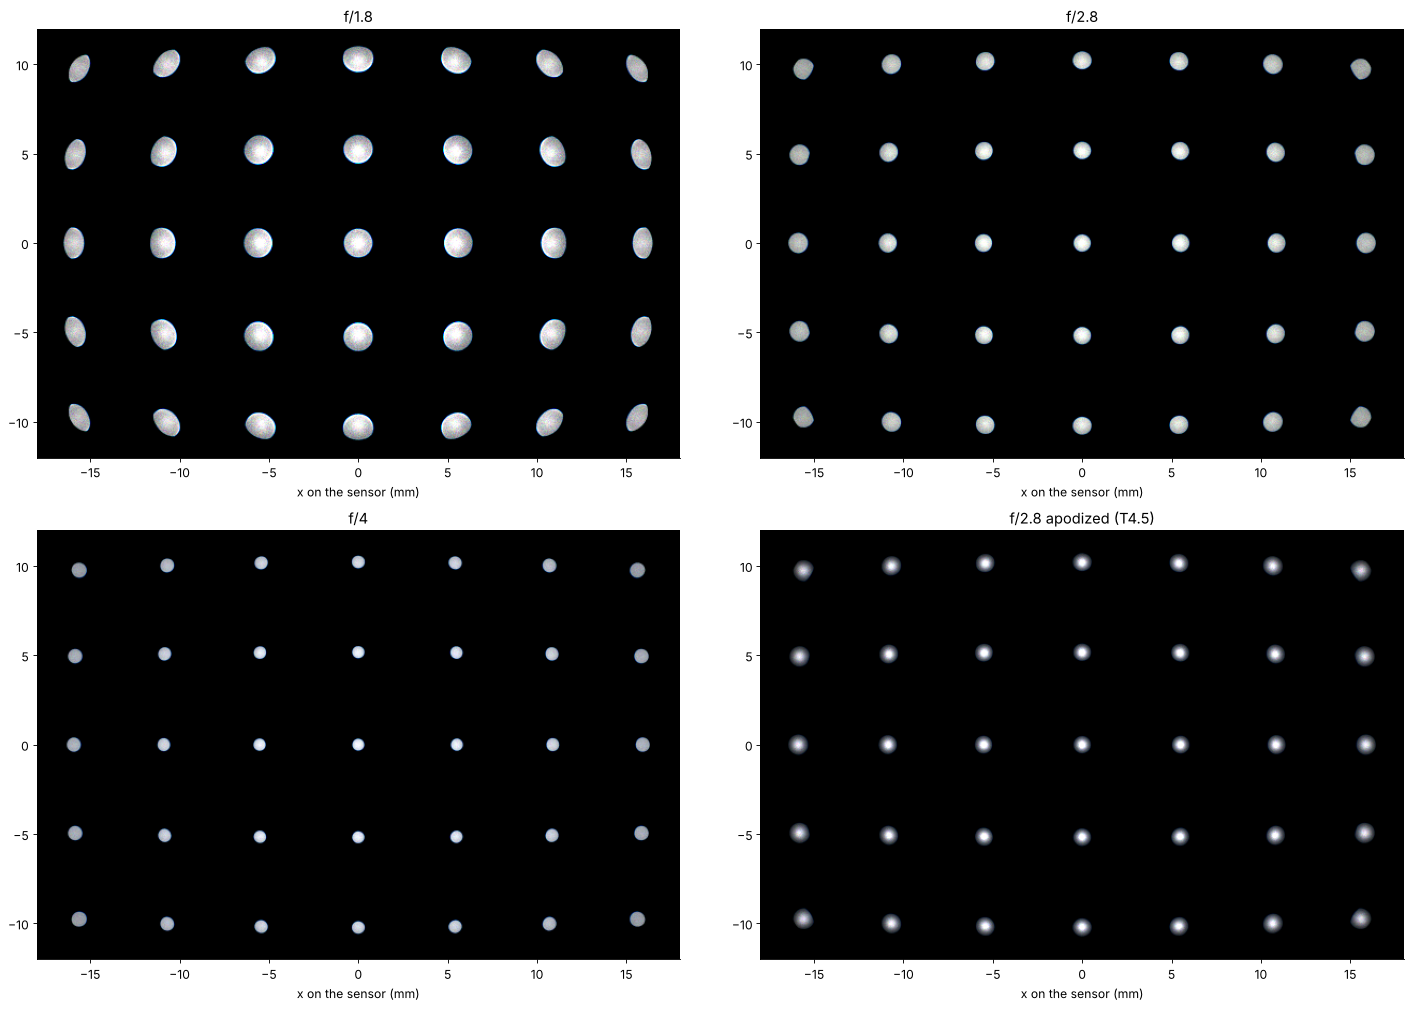

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(18, 12.5), layout="constrained")
i0, j0 = np.searchsorted(ye, 0) - 1, np.searchsorted(xe, 0) - 1
for a, (key, img) in zip(ax.ravel(), renders.items()):
    # exposed for the light in the centre (its mean over the blur, in each colour)
    centre = img[i0 - 20:i0 + 21, j0 - 20:j0 + 21]
    ref = np.array([c[c > 0.2*c.max()].mean() for c in np.moveaxis(centre, -1, 0)])
    a.imshow(np.clip(img/ref*0.8, 0, 1)**0.7, extent=[xe[0], xe[-1], ye[0], ye[-1]], origin="lower")
    a.set_title(key)
    a.set_xlabel("x on the sensor (mm)")
    a.set_facecolor("k")
plt.show()

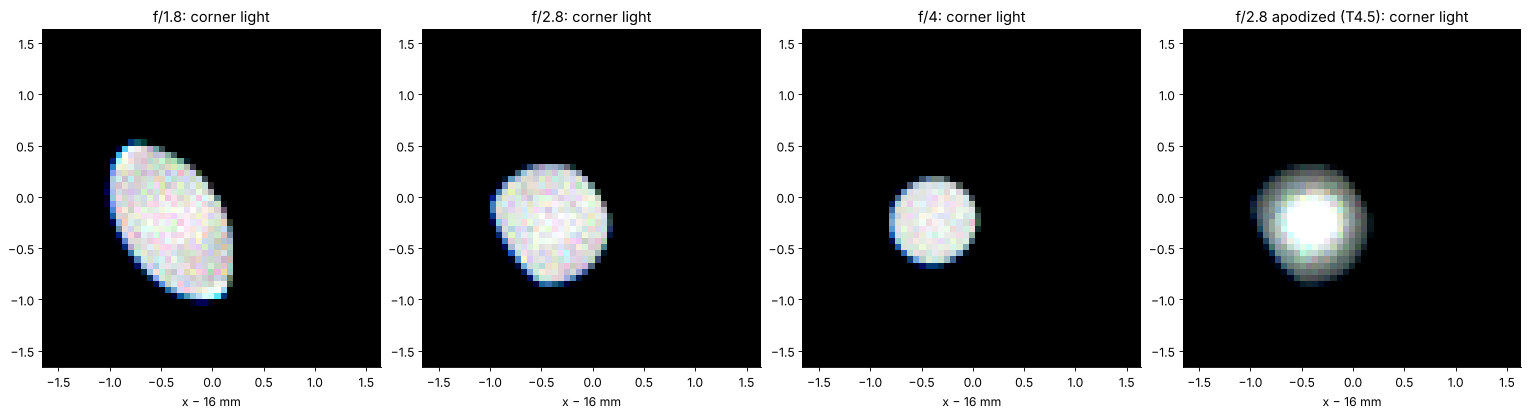

In [24]:
fig, ax = plt.subplots(1, 4, figsize=(19, 5), layout="constrained")
for a, (key, img) in zip(ax, renders.items()):
    j0, i0 = np.searchsorted(xe, 16) - 1, np.searchsorted(ye, 10) - 1
    crop = img[i0 - 27:i0 + 28, j0 - 27:j0 + 28]
    ref = np.array([c[c > 0.2*c.max()].mean() for c in np.moveaxis(crop, -1, 0)])
    a.imshow(np.clip(crop/ref*0.8, 0, 1)**0.7, origin="lower",
             extent=[xe[j0 - 27] - 16, xe[j0 + 28] - 16, ye[i0 - 27] - 10, ye[i0 + 28] - 10])
    a.set_title(key + ": corner light")
    a.set_xlabel("x − 16 mm")
plt.show()

At f/1.8 the blurs are round in the middle and turn into cat's eyes
towards the corners, oriented along circles around the centre (swirl).
They pass less light there, but the irradiance inside them stays about
the same: the light is lost with the area of the blur. At f/2.8 only the
corners are cut, at f/4 none are. The
apodized lens gives soft balls. The edges of the blurs are coloured: the
spherical aberration differs between the colours (spherochromatism), so
the rims of the F, d and C blurs do not coincide; the zoom into the upper
right corner shows the blue fringe on the outer edge of the cat's eye.

## Summary

- The blur of an out-of-focus point is a shadow of the pupil. Its size is
  $c = f^2|s - s_f|/(N s (s_f - f))$ for a thin lens and
  $m_p D|x_s - x'|/(x' + m_p f)$ from the pupils (exact in first order);
  real rays wide open differ by the spherical aberration, which also moves
  the best focus (0.33 mm here at f/1.8).
- The irradiance across the blur is $\rho/(\pi r|dr/d\rho|)$ with
  $r = dW/d\rho$. Undercorrected spherical aberration gives a soft
  background and a bright-rimmed (soap bubble) foreground, and bright rims
  turn lines into double lines. With more than about ten waves of defocus,
  the blur is geometric; a point at infinity seen by a 50 mm lens focused at
  1 m has 145.
- Off the axis, the rims of the front and rear elements cut the beam into
  a cat's eye, which the paraxial vignetting circles describe (with real
  rays passing 3 to 8 points more light). At f/1.8 the corners get a third
  of the light, from f/4 on there is no vignetting.
- A ripple of a few tens of nanometres on an asphere makes onion rings
  with a contrast of tens of percent: $2\pi^2A/(|W_{020}|p^2)$ from rays
  (the local defocus including the spherical aberration), limited by the
  Talbot effect to $4\pi A|\sin(\pi/(2|W_{020}|p^2))|$.
- A Gaussian apodizer that turns f/2.8 into T4.5 gives bell-shaped blurs,
  keeps the f/2.8 cutoff and removes the Airy rings, with an MTF between
  that of f/2.8 and f/4.5.

In [25]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 75 s


## References

- H. H. Nasse, "Depth of field and bokeh", Carl Zeiss Camera Lens
  Division (2010).
- H. H. Nasse, "How to read MTF curves, part II", Carl Zeiss Camera Lens
  Division (2009), on vignetting and the cat's eye.
- R. Kingslake, *A History of the Photographic Lens*, Academic Press
  (1989), chapter 9 (the double Gauss).
- W. J. Smith, *Modern Lens Design*, 2nd ed., McGraw-Hill (2005),
  chapter 15 (double Gauss lenses).
- M. Born and E. Wolf, *Principles of Optics*, 7th ed., Cambridge
  University Press (1999), sections 8.8 and 9.2.
- J. W. Goodman, *Introduction to Fourier Optics*, 3rd ed., Roberts
  (2005), sections 4.5 (Talbot images) and 6.4 (apodization).
- M. R. Teague, "Deterministic phase retrieval: a Green's function
  solution", J. Opt. Soc. Am. 73, 1434–1441 (1983).
- P. Jacquinot and B. Roizen-Dossier, "Apodisation", Prog. Opt. 3, 29–186
  (1964).